# Cargar Datos

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# Cargar CIFAR-10
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

class_names = [
    "Avión","Automóvil","Pájaro","Gato","Ciervo",
    "Perro","Rana","Caballo","Barco","Camión"
]

# Normalización
x_train = x_train.astype("float32") / 255.
x_test  = x_test.astype("float32") / 255.

# ============================================
# Reducir el conjunto para provocar overfitting
# (Solo para fines didácticos)
# ============================================
x_train = x_train[:8000]
y_train = y_train[:8000]

# Mostrar algunas imágenes

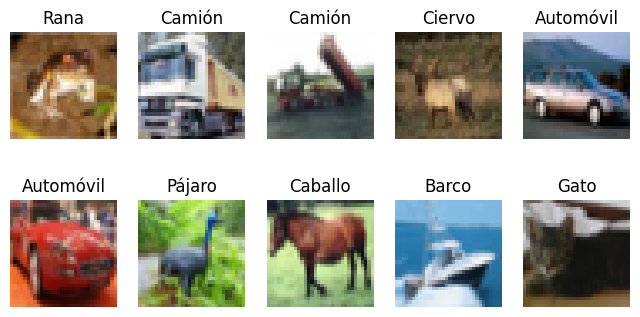

In [8]:
plt.figure(figsize=(8,4))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.show()

# Definir Data Augmentation

In [22]:
data_augmentation = keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.15),

    layers.RandomTranslation(0.1,0.1)

])

# Visualizar el efecto

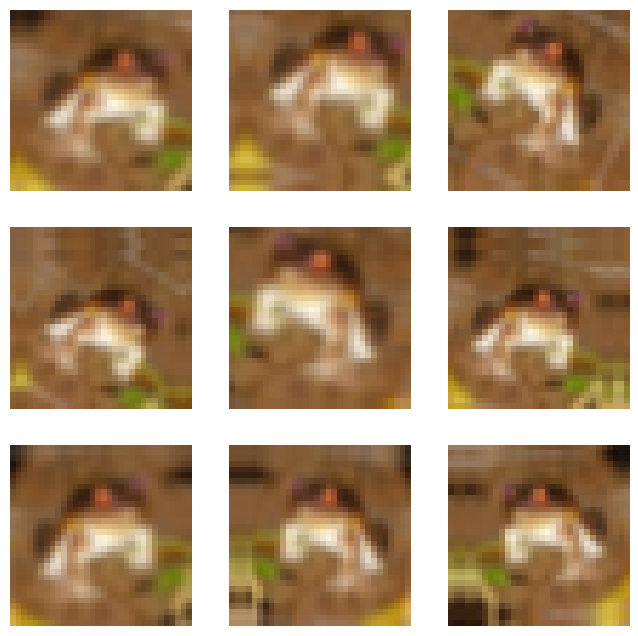

In [25]:
plt.figure(figsize=(8,8))

image = x_train[0]

for i in range(9):

    ax = plt.subplot(3,3,i+1)

    augmented = data_augmentation(
        tf.expand_dims(image,0)
    )

    plt.imshow(augmented[0])

    plt.axis("off")

plt.show()

# Función para construir la CNN

In [26]:
def create_model(use_augmentation=False):
    model = keras.Sequential()
    
    if use_augmentation:
        model.add(data_augmentation)
        
    model.add(layers.Conv2D(32,3,padding="same",activation="relu",input_shape=(32,32,3)))
    model.add(layers.MaxPooling2D())
    
    model.add(layers.Conv2D(64,3,padding="same",activation="relu"))
    model.add(layers.MaxPooling2D())
    
    model.add(layers.Conv2D(128,3,padding="same",activation="relu"))
    model.add(layers.Flatten())
    
    model.add(layers.Dense(128,activation="relu"))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(10,activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Entrenar SIN augmentation

In [12]:
model_base = create_model(False)

history_base = model_base.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    verbose=1
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.2672 - loss: 1.9816 - val_accuracy: 0.3744 - val_loss: 1.7504
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.3977 - loss: 1.6336 - val_accuracy: 0.4344 - val_loss: 1.5540
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.4638 - loss: 1.4732 - val_accuracy: 0.4975 - val_loss: 1.4070
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.5178 - loss: 1.3408 - val_accuracy: 0.5013 - val_loss: 1.3938
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.5653 - loss: 1.2118 - val_accuracy: 0.5344 - val_loss: 1.3132
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.6059 - loss: 1.1111 - val_accuracy: 0.5344 - val_loss: 1.2720
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.6439 - loss: 1.0091 - val_accuracy: 0.5537 - val_loss: 1.2292
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.6712 - loss: 0.9038 - val_accu

# Entrenar CON augmentation

In [27]:
model_aug = create_model(True)

history_aug = model_aug.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    verbose=1

)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.2058 - loss: 2.0878 - val_accuracy: 0.3125 - val_loss: 1.8906
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.3225 - loss: 1.8555 - val_accuracy: 0.3381 - val_loss: 1.7891
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.3675 - loss: 1.7324 - val_accuracy: 0.3975 - val_loss: 1.6823
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.3784 - loss: 1.6963 - val_accuracy: 0.4300 - val_loss: 1.5861
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.4136 - loss: 1.6321 - val_accuracy: 0.3787 - val_loss: 1.8403
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.4225 - loss: 1.5877 - val_accuracy: 0.4844 - val_loss: 1.4932
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.4353 - loss: 1.5632 - val_accuracy: 0.4412 - val_loss: 1.5464
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.4511 - loss: 1.5194 - val_accu

# Comparar curvas

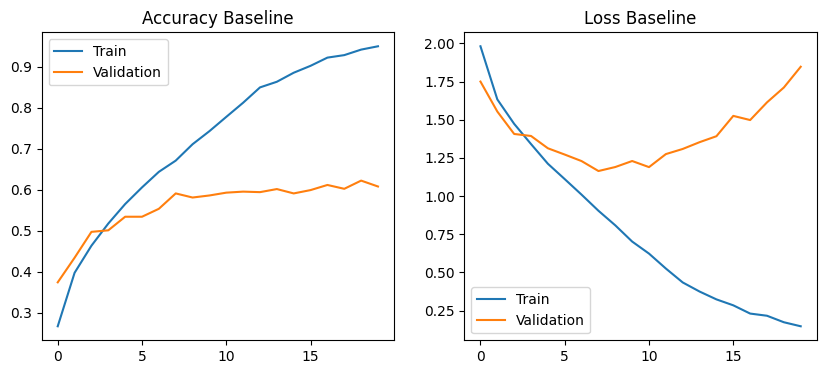

In [28]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history_base.history['accuracy'],label='Train')
plt.plot(history_base.history['val_accuracy'],label='Validation')
plt.legend()
plt.title("Accuracy Baseline")

plt.subplot(1,2,2)
plt.plot(history_base.history['loss'],label='Train')
plt.plot(history_base.history['val_loss'],label='Validation')
plt.legend()
plt.title("Loss Baseline")

plt.show()


Se observa un claro fenómeno de overfitting.

Las evidencias son:

- La accuracy de entrenamiento continúa aumentando hasta aproximadamente un 95%.
- La accuracy de validación se estabiliza alrededor del 60%, sin presentar mejoras significativas.
- La pérdida de entrenamiento disminuye continuamente durante todas las épocas.
- La pérdida de validación comienza a aumentar aproximadamente desde la época 8, indicando que el modelo comienza a memorizar el conjunto de entrenamiento y pierde capacidad de generalización.

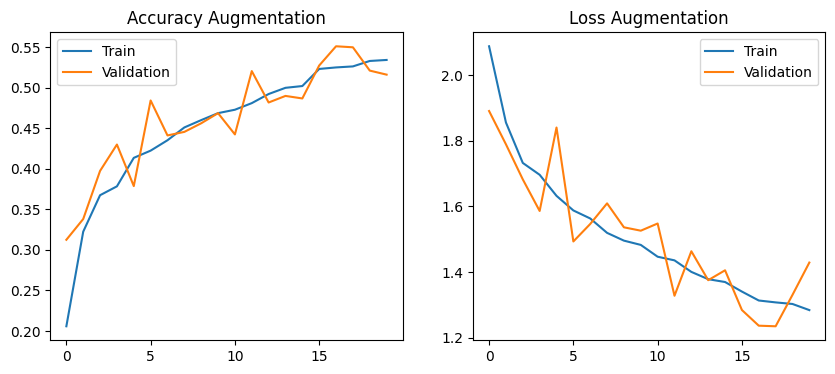

In [29]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history_aug.history['accuracy'],label='Train')
plt.plot(history_aug.history['val_accuracy'],label='Validation')
plt.legend()
plt.title("Accuracy Augmentation")

plt.subplot(1,2,2)
plt.plot(history_aug.history['loss'],label='Train')
plt.plot(history_aug.history['val_loss'],label='Validation')
plt.legend()
plt.title("Loss Augmentation")

plt.show()

Al incorporar **Data Augmentation**, las curvas de aprendizaje muestran un comportamiento significativamente más estable que el observado en el modelo base. La diferencia entre las curvas de entrenamiento y validación disminuye considerablemente, mientras que la pérdida de validación deja de aumentar y sigue una tendencia similar a la pérdida de entrenamiento. Esto indica que el modelo ha reducido el sobreajuste y ha mejorado su capacidad de **generalizar** frente a imágenes que no ha visto durante el entrenamiento. En otras palabras, el modelo ya no memoriza ejemplos específicos del conjunto de entrenamiento, sino que aprende representaciones más robustas del objeto al enfrentarse a múltiples variaciones de una misma imagen.


# Evaluar en Test

In [21]:
loss_base,acc_base = model_base.evaluate(
    x_test,
    y_test,
    verbose=0
)

loss_aug,acc_aug = model_aug.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Sin augmentation : {acc_base*100:.3f}")

print(f"Con augmentation : {acc_aug*100:.3f}")

Sin augmentation : 60.580
Con augmentation : 56.330


Sin embargo, al evaluar el conjunto de prueba se observa que la exactitud disminuye ligeramente, pasando de **60.58%** a **56.33%**. A primera vista esto podría interpretarse como un peor modelo, pero este resultado pone de manifiesto una idea fundamental en Deep Learning: **la accuracy por sí sola no es suficiente para evaluar el desempeño de un modelo**. Las curvas de aprendizaje muestran una clara reducción del sobreajuste, lo que significa que el modelo ahora generaliza mejor, aunque todavía no alcanza un nivel de precisión satisfactorio. Esto sugiere que el aumento de datos, por sí solo, no siempre es suficiente para obtener el mejor rendimiento posible. Para seguir mejorando el modelo es necesario combinar esta técnica con otras estrategias de regularización, como **Dropout**, **Early Stopping**, **Batch Normalization** o ajustes en la arquitectura de la red. El objetivo final no es únicamente reducir el sobreajuste, sino encontrar un equilibrio entre una buena capacidad de generalización y un alto desempeño sobre datos nunca vistos.


In [32]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def evaluar_modelo(model, x_test, y_test, class_names):
    # Predicciones
    y_pred = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_pred, axis=1)
    y_true = y_test.flatten()

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.title("Matriz de Confusión")
    plt.show()

    print("\nClassification Report\n")
    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names
    ))

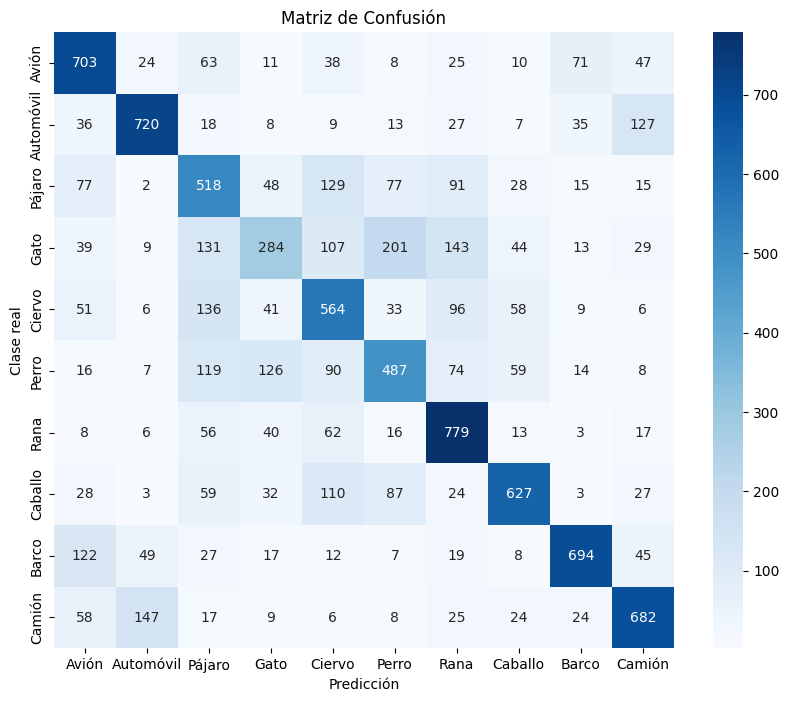


Classification Report

              precision    recall  f1-score   support

       Avión       0.62      0.70      0.66      1000
   Automóvil       0.74      0.72      0.73      1000
      Pájaro       0.45      0.52      0.48      1000
        Gato       0.46      0.28      0.35      1000
      Ciervo       0.50      0.56      0.53      1000
       Perro       0.52      0.49      0.50      1000
        Rana       0.60      0.78      0.68      1000
     Caballo       0.71      0.63      0.67      1000
       Barco       0.79      0.69      0.74      1000
      Camión       0.68      0.68      0.68      1000

    accuracy                           0.61     10000
   macro avg       0.61      0.61      0.60     10000
weighted avg       0.61      0.61      0.60     10000



In [33]:
evaluar_modelo(model_base, x_test, y_test, class_names)

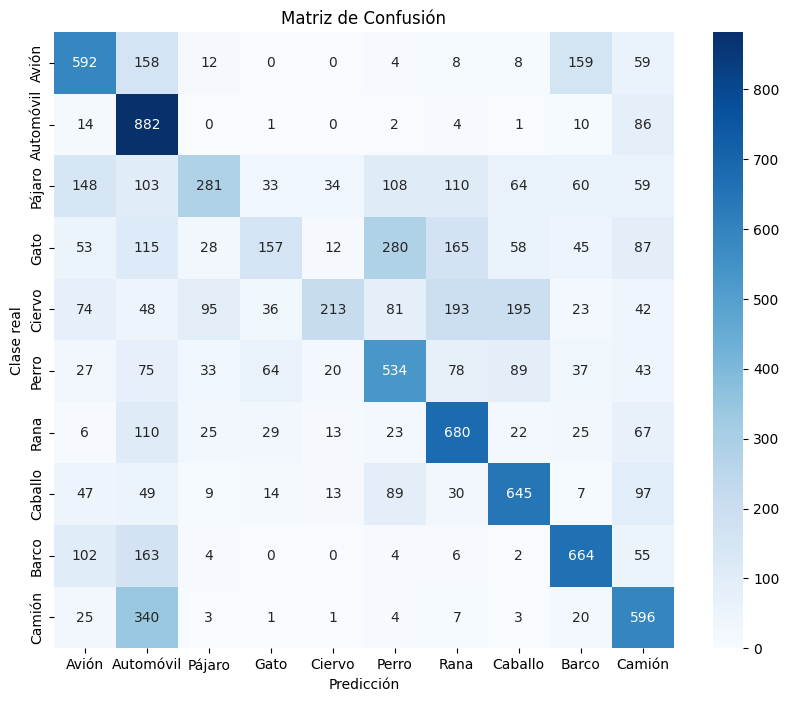


Classification Report

              precision    recall  f1-score   support

       Avión       0.54      0.59      0.57      1000
   Automóvil       0.43      0.88      0.58      1000
      Pájaro       0.57      0.28      0.38      1000
        Gato       0.47      0.16      0.24      1000
      Ciervo       0.70      0.21      0.33      1000
       Perro       0.47      0.53      0.50      1000
        Rana       0.53      0.68      0.60      1000
     Caballo       0.59      0.65      0.62      1000
       Barco       0.63      0.66      0.65      1000
      Camión       0.50      0.60      0.54      1000

    accuracy                           0.52     10000
   macro avg       0.54      0.52      0.50     10000
weighted avg       0.54      0.52      0.50     10000



In [34]:
evaluar_modelo(model_aug, x_test, y_test, class_names)